In [1]:
import os.path
import gc
import pandas as pd
import pickle as pkl
import torch
import numpy as np
import random
from tqdm import tqdm
import json
from sklearn import metrics
from utils import get_texts_for_ptype
from sklearn import metrics
from scipy.optimize import minimize_scalar
import datasets
from datasets import load_metric

from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification
from transformers import TrainingArguments, Trainer
from datasets import load_dataset
from matplotlib import pyplot as plt

<frozen importlib._bootstrap>:241: RuntimeWarning: pyarrow.lib.Tensor size changed, may indicate binary incompatibility. Expected 64 from C header, got 80 from PyObject
/home/k2141255/anaconda3/envs/study_design_classifier_bert/lib/python3.11/site-packages/torch/cuda/__init__.py:611: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


In [2]:
neg_to_pos_ratio = 1
results_file = "results_titles_abstracts_bert_experiments.json"
    
with open(results_file, "r") as f:
    results_list = json.load(f)
    
inputs = "titles_abstracts"

with open("../data/cleaned_pos_neg_train_val_test_dataset_ids.pkl", "rb") as f:
    prop_typ_id_dict = pkl.load(f)

ptypes = prop_typ_id_dict.keys()
    
metrics_list = []
metric_acc = load_metric("accuracy")
metric_p = load_metric("precision")
metric_r = load_metric("recall")
metric_f = load_metric("f1")

/tmp/ipykernel_70018/2494697924.py:15: FutureWarning: load_metric is deprecated and will be removed in the next major version of datasets. Use 'evaluate.load' instead, from the new library 🤗 Evaluate: https://huggingface.co/docs/evaluate
  metric_acc = load_metric("accuracy")
/home/k2141255/anaconda3/envs/study_design_classifier_bert/lib/python3.11/site-packages/datasets/load.py:759: FutureWarning: The repository for accuracy contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.19.1/metrics/accuracy/accuracy.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(
/home/k2141255/anaconda3/envs/study_design_classifier_bert/lib/python3.11/site-packages/datasets/load.py:759: FutureWarning: The repository for p

In [3]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    acc = metric_acc.compute(predictions=predictions, references=labels)['accuracy']
    p = metric_p.compute(predictions=predictions, references=labels)['precision']
    r = metric_r.compute(predictions=predictions, references=labels)['recall']
    f = metric_f.compute(predictions=predictions, references=labels)['f1']
    return {'accuracy': acc, 'precision': p, 'recall': r, 'f1': f}

In [4]:
ptype = "is_sr"
model_type = "distilbert-base-uncased"
# saved_model = "is_guideline_bert-base-cased"


In [5]:
PATH = f'trained/{ptype}_{model_type}/'
def model_init():
    return AutoModelForSequenceClassification.from_pretrained(PATH)


In [6]:
len(results_list)

25

In [7]:
results_json = [json for json in results_list if json['ptype'] == ptype and json['model_type'] == model_type][0]

In [8]:
results_json

{'ptype': 'is_sr',
 'model_type': 'distilbert-base-uncased',
 'neg_to_pos_ratio': 1,
 'num_train_epochs': 2,
 'learning_rate': 6.951927961775605e-06,
 'seed': 983,
 'batch_size': 8,
 'recall_val': 1.0,
 'spec_val': 0.926829268292683,
 'precision_val_even': 0.9285714285714286,
 'f1_val_even': 0.9629629629629629,
 'accuracy_val': 0.9625,
 'recall_test': 0.97225,
 'spec_test': 0.95825,
 'precision_test_even': 0.9588264299802761,
 'f1_test_even': 0.9654915590863953,
 'accuracy_test': 0.96525}

In [9]:
ptype

'is_sr'

In [10]:
# def model_init():
#     return AutoModelForSequenceClassification.from_pretrained(model_type, return_dict=False, force_download=True)

# X_train, X_val, X_test, y_train, y_val, y_test = get_texts_for_ptype(ptype, inputs="titles_abstracts", neg_to_pos_ratio=neg_to_pos_ratio)
    
# train = pd.DataFrame()
# train['label'] = y_train
# train['text'] = list(X_train)

# val = pd.DataFrame()
# val['label'] = y_val
# val['text'] = list(X_val)

# test = pd.DataFrame()
# test['label'] = y_test
# test['text'] = list(X_test)

# train_dataset = datasets.Dataset.from_pandas(train.reset_index(drop=True))
# val_dataset = datasets.Dataset.from_pandas(val.reset_index(drop=True))
# test_dataset = datasets.Dataset.from_pandas(test.reset_index(drop=True))

# dataset = datasets.dataset_dict.DatasetDict(
#     {
#         'train': train_dataset,
#         'val': val_dataset,
#         'test': test_dataset
#     }
# )
    
# tokenizer = AutoTokenizer.from_pretrained(model_type)
# def tokenize_function(examples):
#     return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=420)

# tokenized_datasets = dataset.map(tokenize_function, batched=True)
    
# train_dataset = tokenized_datasets['train'].map(tokenize_function, batched=True)
# val_dataset = tokenized_datasets['val'].map(tokenize_function, batched=True)
# test_dataset = tokenized_datasets['test'].map(tokenize_function, batched=True)
        
# train_dataset = train_dataset.shuffle(seed=42)
# val_dataset = val_dataset.shuffle(seed=42)
# test_dataset = test_dataset.shuffle(seed=42)

In [11]:
# training_args = TrainingArguments(output_dir="test_trainer",
#                                       num_train_epochs=results_json["num_train_epochs"],
#                                       learning_rate=results_json["learning_rate"],
#                                       seed=results_json["seed"],
#                                       per_device_train_batch_size=results_json["batch_size"],
#                                       dataloader_num_workers = 1
#                                      )
        
# trainer = Trainer(
#         args=training_args,
#         train_dataset=train_dataset,
#         compute_metrics=compute_metrics,
#         model_init=model_init
# )

# trainer.train()
 
# outputs = trainer.predict(test_dataset)

In [12]:
def get_scores(predictions):
    return [np.exp(p[1])/(np.exp(p[0]) + np.exp(p[1])) for p in predictions]

In [13]:
def find_db(db):
    y_pred_test = predict(scores, db)
    recall_test = metrics.recall_score(labels, y_pred_test, pos_label=1)
    return abs(recall_test - 0.985)

In [14]:
def predict(scores, db=0):
    return [int(x>=db) for x in scores]

In [15]:
neg_pos_ratio_dict = {
    "is_rct": 5585042/489295,
    "is_sr": 5659292/121063,
    "is_casecontrol": 5628219/65790,
    "is_cohort": 5632460/78688,
    "is_guideline": 5676411/33826
}

def calc_precision(recall, specificity, neg_pos_ratio):
    return recall / (recall + neg_pos_ratio * (1 - specificity) + 1e-15)

def calc_f1(recall, precision):
    return 2*recall*precision/(recall+precision + 1e-15)

In [16]:
bert_fixed_outputs_path = "bert_fixed_outputs.pkl"
with open(bert_fixed_outputs_path, "rb") as f:
    outputs_dict = pkl.load(f)
len(outputs_dict)

25

In [17]:
outputs_dict.keys()

dict_keys(['is_rct_distilbert-base-uncased', 'is_rct_bert-base-cased', 'is_rct_allenai/scibert_scivocab_uncased', 'is_rct_dmis-lab/biobert-base-cased-v1.2', 'is_rct_microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext', 'is_sr_distilbert-base-uncased', 'is_sr_bert-base-cased', 'is_sr_allenai/scibert_scivocab_uncased', 'is_sr_dmis-lab/biobert-base-cased-v1.2', 'is_sr_microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext', 'is_casecontrol_distilbert-base-uncased', 'is_casecontrol_bert-base-cased', 'is_casecontrol_allenai/scibert_scivocab_uncased', 'is_casecontrol_dmis-lab/biobert-base-cased-v1.2', 'is_casecontrol_microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext', 'is_cohort_distilbert-base-uncased', 'is_cohort_bert-base-cased', 'is_cohort_allenai/scibert_scivocab_uncased', 'is_cohort_dmis-lab/biobert-base-cased-v1.2', 'is_cohort_microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext', 'is_guideline_distilbert-base-uncased', 'is_guideline_bert-base-cas

In [123]:
key = list(outputs_dict.keys())[24]
ptype = 'is_guideline'
value = outputs_dict[key]
predictions = value.predictions
labels = value.label_ids
scores = get_scores(predictions)
auc_roc = metrics.roc_auc_score(labels, scores)
print(ptype, key)
print("AUCROC:", auc_roc)
# res = minimize_scalar(find_db)
# db = res['x']
db = 0.010482
y_pred_test = predict(scores, db)        
recall_test = metrics.recall_score(labels, y_pred_test, pos_label=1)
print("Recall:", recall_test)
spec_test = metrics.recall_score(labels, y_pred_test, pos_label=0)
print("Specificity:", spec_test)
precision_test = calc_precision(recall_test, spec_test, neg_pos_ratio_dict[ptype])
print("Precision:", precision_test)
# f1_test = calc_f1(recall_test, precision_test)
# print("F1:", f1_test)

is_guideline is_guideline_microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
AUCROC: 0.9963635937499999
Recall: 0.985
Specificity: 0.96275
Precision: 0.1361249399384161


In [116]:
fpr, tpr, thresholds = metrics.roc_curve(labels, scores)

In [121]:
pd.DataFrame(
    {
        "threshold": thresholds,
        "TPR": tpr
    }
)[1200:1250]

,threshold,TPR
1200,0.091858,0.97950
1201,0.084829,0.98025
1202,0.073956,0.98025
1203,0.062588,0.98050
1204,0.060808,0.98050
1205,0.060722,0.98075
1206,0.056435,0.98075
1207,0.053031,0.98100
1208,0.051167,0.98100
1209,0.050797,0.98125


In [37]:
for key, value in outputs_dict.items():
    if 'guideline' in key:
        print(key)
        predictions = value.predictions
        labels = value.label_ids
        scores = get_scores(predictions)
        auc_roc = metrics.roc_auc_score(labels, scores)
        print("AUCROC:", auc_roc)
        res = minimize_scalar(find_db)
        db = res['x']
        # db = 0.000235
        y_pred_test = predict(scores, db)        
        recall_test = metrics.recall_score(labels, y_pred_test, pos_label=1)
        print("Recall:", recall_test)
        spec_test = metrics.recall_score(labels, y_pred_test, pos_label=0)
        print("Specificity:", spec_test)
        precision_test = calc_precision(recall_test, spec_test, neg_pos_ratio_dict[ptype])
        print("Precision:", precision_test)
        f1_test = calc_f1(recall_test, precision_test)
        print("F1:", f1_test)

is_guideline_distilbert-base-uncased
AUCROC: 0.99546465625
Recall: 1.0
Specificity: 0.0
Precision: 0.08055117784871006
F1: 0.1490927583996176
is_guideline_bert-base-cased
AUCROC: 0.9923695312500002
Recall: 1.0
Specificity: 0.0
Precision: 0.08055117784871006
F1: 0.1490927583996176
is_guideline_allenai/scibert_scivocab_uncased
AUCROC: 0.99595734375
Recall: 1.0
Specificity: 0.0
Precision: 0.08055117784871006
F1: 0.1490927583996176
is_guideline_dmis-lab/biobert-base-cased-v1.2
AUCROC: 0.9963260625000001
Recall: 1.0
Specificity: 0.0
Precision: 0.08055117784871006
F1: 0.1490927583996176
is_guideline_microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
AUCROC: 0.9963635937499999
Recall: 1.0
Specificity: 0.0
Precision: 0.08055117784871006
F1: 0.1490927583996176


In [ ]:
# fpr, tpr, thresholds = metrics.roc_curve(labels, scores)
# plt.plot(fpr, tpr)

In [290]:
outputs_check = outputs_dict['is_rct_distilbert-base-uncased']
outputs_check

PredictionOutput(predictions=array([[ 3.4412136, -3.8137817],
       [-3.3121853,  3.7945151],
       [-3.31801  ,  3.8104353],
       ...,
       [-3.2915049,  3.764046 ],
       [-3.3169687,  3.804303 ],
       [-3.3215442,  3.8063653]], dtype=float32), label_ids=array([0, 1, 1, ..., 1, 1, 1]), metrics={'test_loss': 0.32649707794189453, 'test_accuracy': 0.935125, 'test_precision': 0.9378616352201258, 'test_recall': 0.932, 'test_f1': 0.9349216300940438, 'test_runtime': 614.8314, 'test_samples_per_second': 13.012, 'test_steps_per_second': 1.626})

array([0, 1, 1, ..., 1, 1, 1])

In [291]:
outputs

PredictionOutput(predictions=array([[-2.0330675,  2.1132808],
       [-2.840541 ,  3.1969526],
       [-2.4037678,  2.5392983],
       ...,
       [-3.3108418,  3.7879596],
       [ 0.2020284, -0.313729 ],
       [ 3.4286435, -3.7987916]], dtype=float32), label_ids=array([1, 1, 0, ..., 1, 0, 0]), metrics={'test_loss': 0.32649707794189453, 'test_accuracy': 0.935125, 'test_precision': 0.9378616352201258, 'test_recall': 0.932, 'test_f1': 0.9349216300940438, 'test_runtime': 1191.7683, 'test_samples_per_second': 6.713, 'test_steps_per_second': 0.839})

In [272]:
test_dataset

Dataset({
    features: ['label', 'text', 'input_ids', 'attention_mask'],
    num_rows: 8000
})

In [293]:
predictions = outputs_check.predictions
scores = get_scores(predictions)
auc_roc = metrics.roc_auc_score(outputs_check.label_ids, scores)

In [294]:
auc_roc

0.9793663125

In [295]:
#     res = minimize_scalar(find_db)
db = 0.000235
y_pred_test = predict(scores, db)
    
recall_test = metrics.recall_score(test_dataset['label'], y_pred_test, pos_label=1)
spec_test = metrics.recall_score(test_dataset['label'], y_pred_test, pos_label=0)
precision_test = calc_precision(recall_test, spec_test, neg_pos_ratio_dict[ptype])
f1_test = calc_f1(recall_test, precision_test)

In [296]:
db

0.000235

In [297]:
recall_test

1.0

In [298]:
spec_test

0.0

In [299]:
precision_test

0.08055117784871006

In [300]:
f1_test

0.1490927583996176

In [285]:
auc_roc

0.97936634375

In [303]:
predictions = outputs.predictions
compute_metrics((predictions, test_dataset['label']))

{'accuracy': 0.935125,
 'precision': 0.9378616352201258,
 'recall': 0.932,
 'f1': 0.9349216300940438}

In [301]:
compute_metrics((predictions, outputs_check.label_ids))

{'accuracy': 0.935125,
 'precision': 0.9378616352201258,
 'recall': 0.932,
 'f1': 0.9349216300940438}

In [287]:
fpr, tpr, thresholds = metrics.roc_curve(test_dataset['label'], scores)

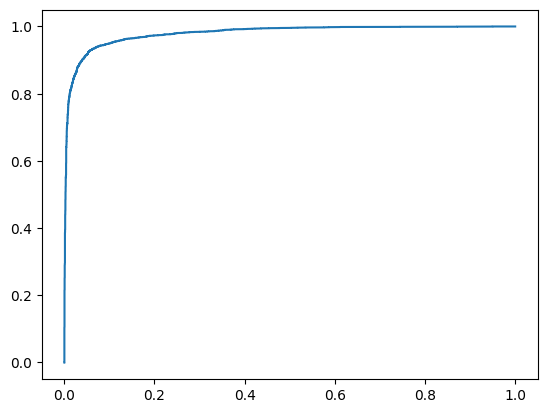

In [194]:
pd.DataFrame({
    "TPR": tpr,
    "Thresholds": thresholds
}).iloc[550:600]

,TPR,Thresholds
550,0.98400,0.000396
551,0.98400,0.000385
552,0.98425,0.000380
553,0.98425,0.000334
554,0.98450,0.000331
555,0.98450,0.000287
556,0.98475,0.000280
557,0.98475,0.000241
558,0.98500,0.000235
559,0.98500,0.000199


In [182]:
thresholds

array([          inf, 9.9998897e-01, 9.9998891e-01, 9.9998868e-01,
       9.9998862e-01, 9.9998856e-01, 9.9998850e-01, 9.9998844e-01,
       9.9998838e-01, 9.9998832e-01, 9.9998826e-01, 9.9998820e-01,
       9.9998814e-01, 9.9998808e-01, 9.9998802e-01, 9.9998796e-01,
       9.9998790e-01, 9.9998784e-01, 9.9998778e-01, 9.9998772e-01,
       9.9998766e-01, 9.9998760e-01, 9.9998754e-01, 9.9998748e-01,
       9.9998742e-01, 9.9998736e-01, 9.9998730e-01, 9.9998724e-01,
       9.9998713e-01, 9.9998707e-01, 9.9998701e-01, 9.9998695e-01,
       9.9998689e-01, 9.9998683e-01, 9.9998677e-01, 9.9998671e-01,
       9.9998665e-01, 9.9998659e-01, 9.9998653e-01, 9.9998647e-01,
       9.9998641e-01, 9.9998635e-01, 9.9998629e-01, 9.9998623e-01,
       9.9998617e-01, 9.9998611e-01, 9.9998605e-01, 9.9998599e-01,
       9.9998593e-01, 9.9998587e-01, 9.9998581e-01, 9.9998575e-01,
       9.9998569e-01, 9.9998564e-01, 9.9998558e-01, 9.9998552e-01,
       9.9998546e-01, 9.9998540e-01, 9.9998534e-01, 9.9998528e

In [ ]:
from tqdm import tqdm
p_success = 0.6

amount = 100
# path_lengths = []
# for _ in tqdm(range(1000)):
path_length = 0
while amount > 0:
        if np.random.random() < p_success:
            amount *=1.05
        else:
            amount *=0.95
        path_length +=1
        print(amount)
#     path_lengths.append(path_length)

105.0
99.75
94.76249999999999
99.50062499999999
104.47565624999999
109.69943906249999
115.18441101562499
120.94363156640624
126.99081314472656
120.64127248749023
126.67333611186474
120.3396693062715
114.32268584095792
120.03882013300581
126.04076113965611
132.34279919663894
125.72565923680698
132.01194219864732
138.6125393085797
145.54316627400868
152.82032458770914
160.4613408170946
168.48440785794932
160.06018746505185
152.05717809179924
159.6600369963892
151.67703514656975
159.26088690389824
151.2978425587033
158.86273468663848
166.80587142097042
158.46557784992189
166.388856742418
158.0694139052971
150.16594321003222
157.67424037053385
149.79052835200716
157.28005476960752
149.41605203112712
141.94524942957077
134.8479869580922
141.59038630599682
148.66990562129666
156.1034009023615
163.90857094747957
155.7131424001056
147.9274852801003
155.32385954410535
163.0900525213106
154.93554989524506
162.68232739000732
170.81644375950768
162.2756215715323
170.38940265010893
178.908872782614

6.975924616648629e+168
7.324720847481061e+168
7.690956889855114e+168
7.306409045362358e+168
6.94108859309424e+168
7.288143022748952e+168
7.6525501738864e+168
8.03517768258072e+168
8.436936566709757e+168
8.01508973837427e+168
7.614335251455555e+168
7.995052014028333e+168
8.39480461472975e+168
8.814544845466238e+168
9.25527208773955e+168
9.718035692126528e+168
9.232133907520201e+168
9.693740602896211e+168
1.0178427633041023e+169
1.0687349014693076e+169
1.122171646542773e+169
1.1782802288699116e+169
1.119366217426416e+169
1.1753345282977368e+169
1.2341012547126237e+169
1.1723961919769925e+169
1.1137763823781428e+169
1.0580875632592356e+169
1.0051831850962737e+169
9.5492402584146e+168
1.002670227133533e+169
1.0528037384902098e+169
1.1054439254147204e+169
1.0501717291439844e+169
1.1026803156011836e+169
1.1578143313812429e+169
1.2157050479503051e+169
1.2764903003478205e+169
1.2126657853304294e+169
1.2732990745969508e+169
1.3369640283267984e+169
1.4038122297431384e+169
1.4740028412302954e+169

1.0447215562758852e+299
1.0969576340896795e+299
1.0421097523851955e+299
1.0942152400044554e+299
1.0395044780042325e+299
1.0914797019044442e+299
1.1460536869996665e+299
1.20335637134965e+299
1.2635241899171326e+299
1.2003479804212759e+299
1.140330581400212e+299
1.0833140523302015e+299
1.0291483497136914e+299
9.776909322280068e+298
1.0265754788394073e+299
1.0779042527813776e+299
1.0240090401423086e+299
1.0752094921494242e+299
1.1289699667568955e+299
1.0725214684190507e+299
1.018895394998098e+299
1.069840164748003e+299
1.1233321729854032e+299
1.0671655643361331e+299
1.0138072861193264e+299
1.0644976504252927e+299
1.1177225329465574e+299
1.0618364062992295e+299
1.114928226614191e+299
1.0591818152834813e+299
1.1121409060476555e+299
1.1677479513500383e+299
1.1093605537825365e+299
1.1648285814716632e+299
1.2230700105452465e+299
1.161916510017984e+299
1.1038206845170847e+299
1.159011718742939e+299
1.216962304680086e+299
1.1561141894460816e+299
1.0983084799737775e+299
1.0433930559750886e+299
9.

inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf


inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf


...

inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf


inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf


inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf


inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf


inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf
inf


In [333]:
path_length

23388594

In [332]:
amount

inf